# 💼 Comparative Evaluation of Machine Learning Models for Salary Prediction

## 📌 Project Overview

This project develops an **End-to-End Machine Learning based Salary Prediction System** to predict employee salary using demographic, educational, and professional attributes.

The dataset contains **375 records** and the following **6 attributes**:

- 👤 Age
- ⚧️ Gender
- 🎓 Education Level
- 💼 Job Title
- 📈 Years of Experience
- 💰 Salary

**Target Variable:** Salary  
**Problem Type:** Regression

After data cleaning and duplicate removal, the final dataset contains **324 valid records**. Categorical features are converted into numerical features using **One-Hot Encoding**, resulting in **181 input features**.

---

## 🎯 Objectives

1. Understand and inspect the salary dataset.
2. Clean the dataset and handle missing values.
3. Remove duplicate records.
4. Convert categorical variables using One-Hot Encoding.
5. Split the data into training and testing sets.
6. Train multiple regression models.
7. Evaluate and compare model performance.
8. Perform hyperparameter tuning.
9. Apply five-fold cross-validation.
10. Perform hypothesis testing using an F-test.
11. Select the best-performing model.
12. Predict salary for an employee.

---

## 🤖 Machine Learning Models

The following regression models were implemented:

- Linear Regression
- Ridge Regression
- Lasso Regression
- Elastic Net Regression
- Decision Tree Regression
- Random Forest Regression
- Gradient Boosting Regression
- Extra Trees Regression

---

## 📊 Evaluation Metrics

The models were evaluated using:

| Metric | Purpose |
|---|---|
| **MAE** | Measures average absolute prediction error |
| **MSE** | Measures squared prediction error |
| **RMSE** | Measures prediction error in salary units |
| **R²** | Measures the proportion of variance explained by the model |

**Lower MAE, MSE, and RMSE → Better performance**  
**Higher R² → Better performance**

---

## 🏆 Final Model

After comparing all models, **Ridge Regression** was selected as the best-performing base model.

**Best R² Score: 0.8943**

Ridge Regression performed well with the high-dimensional feature set generated through One-Hot Encoding.

---

## 🧪 Hypothesis Testing

An overall **F-test** was performed to determine whether there is a statistically significant relationship between the predictor variables and Salary.

- **R²:** 0.8943
- **F-statistic:** 3.5993
- **Degrees of Freedom:** (181, 77)
- **p-value:** 1.2512 × 10⁻⁹
- **Significance Level (α):** 0.05

Since:

**p-value < 0.05**

the null hypothesis is **rejected**.

### Conclusion

The results indicate a **statistically significant overall relationship** between the predictor variables and Salary. The combination of a **high R² and low p-value** indicates strong model performance and statistical significance.

---

## ⚙️ Model Optimization

Hyperparameter tuning was performed on selected models to identify suitable parameter values and improve model performance.

**Five-fold cross-validation** was also performed to evaluate the reliability and generalization capability of the selected model.

---

## 🔍 Prediction

The final trained model can predict salary using:

**Age + Gender + Education Level + Job Title + Years of Experience**

Prediction error analysis was also performed by comparing the **actual salary, predicted salary, and absolute error**.

---

## 🛠️ Tools & Libraries

**Language:** Python  
**Environment:** Visual Studio Code + Jupyter Notebook

**Libraries:**

`Pandas` • `NumPy` • `Matplotlib` • `Seaborn` • `Scikit-learn` • `Statsmodels` • `Joblib`

---

## 📌 Project Title

### **Comparative Evaluation of Machine Learning Models for Salary Prediction Using Employee Attributes**

## 1. Import Libraries 

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy.stats import f

warnings.filterwarnings("ignore")

In [2]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Load Dataset

In [3]:
# Load the dataset
df = pd.read_csv("C:\\Users\\devis\\OneDrive\\Desktop\\Salary_Prediction_Project\\data\\raw\\Salary _Data.csv")

# Display the first 5 rows
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [4]:
df.describe()

,Age,Years of Experience,Salary
count,373.000000,373.000000,373.000000
mean,37.431635,10.030831,100577.345845
std,7.069073,6.557007,48240.013482
min,23.000000,0.000000,350.000000
25%,31.000000,4.000000,55000.000000
50%,36.000000,9.000000,95000.000000
75%,44.000000,15.000000,140000.000000
max,53.000000,25.000000,250000.000000


## 3. Dataset Overview

In [5]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display basic information
print("\nDataset Information:")
df.info()

Dataset Shape: (375, 6)

Column Names:
Index(['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience',
       'Salary'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    str    
 2   Education Level      373 non-null    str    
 3   Job Title            373 non-null    str    
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), str(3)
memory usage: 17.7 KB


## 4. Data Cleaning

In [6]:
# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())
print(df.isnull().sum())




Duplicate Rows: 50
Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64


In [7]:
df = df.drop_duplicates()
print("\nDuplicate Rows:", df.duplicated().sum())
print(df.isnull().sum())


Duplicate Rows: 0
Age                    1
Gender                 1
Education Level        1
Job Title              1
Years of Experience    1
Salary                 1
dtype: int64


In [8]:
df.shape

(325, 6)

In [9]:
print(df.isnull().sum())

Age                    1
Gender                 1
Education Level        1
Job Title              1
Years of Experience    1
Salary                 1
dtype: int64


## 5.Handling Missing values 

In [10]:
# Remove completely empty rows
df = df.dropna(how="all")

# Remove duplicate rows
df = df.drop_duplicates()

# Verify cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:", df.duplicated().sum())
print("Final dataset shape:", df.shape)

Missing values after cleaning:
Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64

Duplicate rows after cleaning: 0
Final dataset shape: (324, 6)


## 6. Convert Categorical Data to Numerical

In [11]:
# Convert categorical columns into numerical values

df = pd.get_dummies(
    df,
    columns=["Gender", "Education Level", "Job Title"],
    dtype=int
)

print("Categorical encoding completed!")
print("New shape:", df.shape)

Categorical encoding completed!
New shape: (324, 182)


In [12]:

df.head()

,Age,Years of Experience,Salary,Gender_Female,Gender_Male,Education Level_Bachelor's,Education Level_Master's,Education Level_PhD,Job Title_Account Manager,Job Title_Accountant,...,Job Title_Supply Chain Manager,Job Title_Technical Recruiter,Job Title_Technical Support Specialist,Job Title_Technical Writer,Job Title_Training Specialist,Job Title_UX Designer,Job Title_UX Researcher,Job Title_VP of Finance,Job Title_VP of Operations,Job Title_Web Developer
0,32.0,5.0,90000.0,0,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,28.0,3.0,65000.0,1,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,45.0,15.0,150000.0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,36.0,7.0,60000.0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,52.0,20.0,200000.0,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 7. Separate Features and Target

In [13]:
# Separate features and target

X = df.drop("Salary", axis=1)
y = df["Salary"]

categorical_features = [
    "Gender",
    "Education Level",
    "Job Title"
]

numerical_features = [
    "Age",
    "Years of Experience"
]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

X shape: (324, 181)
y shape: (324,)
Categorical features: ['Gender', 'Education Level', 'Job Title']
Numerical features: ['Age', 'Years of Experience']


## 8. Train-Test Split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (259, 181)
X_test : (65, 181)
y_train: (259,)
y_test : (65,)


In [26]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


### 9.Model Training

### 9.1 Linear Regression

### 9.2 Ridge Regression

### 9.3 Lasso Regression

### 9.5 Decision Tree Regression

### 9.7 Gradient Boosting Regression

### 9.8 Extra Trees Regression

In [27]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Elastic Net": ElasticNet(alpha=0.01, l1_ratio=0.5),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

results_df

ValueError: Some column names are not columns of the dataframe: {'Job Title', 'Gender', 'Education Level'}

## 10.Hyperparameter Tuning - Ridge Regression

In [ ]:
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

ridge_params = {
    "model__alpha": [
        0.01,
        0.1,
        1,
        10,
        100,
        1000
    ]
}

ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

tuned_ridge = ridge_grid.best_estimator_

print("Best Ridge Parameters:")
print(ridge_grid.best_params_)

print("\nBest CV R²:")
print(ridge_grid.best_score_)

Best Alpha: 1


## 11.Evaluate Tuned Ridge Regression

In [ ]:
tuned_ridge_pred = tuned_ridge.predict(X_test)

tuned_ridge_mae = mean_absolute_error(
    y_test,
    tuned_ridge_pred
)

tuned_ridge_mse = mean_squared_error(
    y_test,
    tuned_ridge_pred
)

tuned_ridge_rmse = np.sqrt(
    tuned_ridge_mse
)

tuned_ridge_r2 = r2_score(
    y_test,
    tuned_ridge_pred
)

print("Tuned Ridge Regression")
print("-" * 35)
print(f"MAE  : {tuned_ridge_mae:.2f}")
print(f"MSE  : {tuned_ridge_mse:.2f}")
print(f"RMSE : {tuned_ridge_rmse:.2f}")
print(f"R²   : {tuned_ridge_r2:.4f}")

Tuned Ridge Regression Results
------------------------------
MAE  : 10202.77
MSE  : 199739632.39
RMSE : 14132.93
R²   : 0.8943


## Hyperparameter Tuning - Extra Trees

In [ ]:
# Hyperparameter Tuning - Extra Trees

from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10]
}

extra = ExtraTreesRegressor(random_state=42)

extra_grid = GridSearchCV(
    extra,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

extra_grid.fit(X_train, y_train)

tuned_extra = extra_grid.best_estimator_

print("Best Parameters:")
print(extra_grid.best_params_)

Best Parameters:
{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}


## 12.Evaluate Tuned Extra Trees

In [ ]:
# Evaluate Tuned Extra Trees

tuned_extra_pred = tuned_extra.predict(X_test)

tuned_extra_mae = mean_absolute_error(y_test, tuned_extra_pred)
tuned_extra_mse = mean_squared_error(y_test, tuned_extra_pred)
tuned_extra_rmse = np.sqrt(tuned_extra_mse)
tuned_extra_r2 = r2_score(y_test, tuned_extra_pred)

print("Tuned Extra Trees Regression Results")
print("-" * 30)
print(f"MAE  : {tuned_extra_mae:.2f}")
print(f"MSE  : {tuned_extra_mse:.2f}")
print(f"RMSE : {tuned_extra_rmse:.2f}")
print(f"R²   : {tuned_extra_r2:.4f}")

Tuned Extra Trees Regression Results
------------------------------
MAE  : 10163.32
MSE  : 202741991.33
RMSE : 14238.75
R²   : 0.8927


## 13.Cross-Validation for Ridge Regression

In [ ]:
cv_scores = cross_val_score(
    tuned_ridge,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("5-Fold Cross-Validation - Tuned Ridge")
print("-" * 45)

for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i}: {score:.4f}")

print(f"\nMean R²: {cv_scores.mean():.4f}")
print(f"Std  R²: {cv_scores.std():.4f}")

Ridge Regression - 5-Fold Cross-Validation
---------------------------------------------
Fold 1 R² : 0.8744
Fold 2 R² : 0.7381
Fold 3 R² : 0.9436
Fold 4 R² : 0.9144
Fold 5 R² : 0.9070
---------------------------------------------
Mean R²    : 0.8755
Std R²     : 0.0721


## 14.Error Analysis - Ridge Regression

In [ ]:
# Error Analysis - Ridge Regression

y_pred = ridge_model.predict(X_test)

error = y_test - y_pred
absolute_error = abs(error)

error_df = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred,
    "Error": error.values,
    "Absolute Error": absolute_error.values
})

print("Error Analysis")
print("-" * 30)
print(f"Mean Absolute Error : ₹{absolute_error.mean():,.2f}")
print(f"Minimum Error       : ₹{absolute_error.min():,.2f}")
print(f"Maximum Error       : ₹{absolute_error.max():,.2f}")

error_df.head(10)

Error Analysis
------------------------------
Mean Absolute Error : ₹10,202.77
Minimum Error       : ₹79.16
Maximum Error       : ₹44,029.54


,Actual Salary,Predicted Salary,Error,Absolute Error
0,100000.0,118606.606895,-18606.606895,18606.606895
1,100000.0,127629.842772,-27629.842772,27629.842772
2,50000.0,51242.904290,-1242.904290,1242.904290
3,110000.0,119381.087031,-9381.087031,9381.087031
4,105000.0,116016.566503,-11016.566503,11016.566503
5,95000.0,102127.582129,-7127.582129,7127.582129
6,45000.0,51022.807264,-6022.807264,6022.807264
7,55000.0,60361.348719,-5361.348719,5361.348719
8,180000.0,170890.795421,9109.204579,9109.204579
9,40000.0,46793.036886,-6793.036886,6793.036886


## 15.Hyperparameter Tuning - Gradient Boosting

In [ ]:
# Hyperparameter Tuning - Gradient Boosting

from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5, 10]
}

gb = GradientBoostingRegressor(random_state=42)

gb_grid = GridSearchCV(
    gb,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

gb_grid.fit(X_train, y_train)

tuned_gb = gb_grid.best_estimator_

print("Best Parameters:")
print(gb_grid.best_params_)

Best Parameters:
{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 200}


## 16.Evaluate Tuned Gradient Boosting

In [ ]:
# Evaluate Tuned Gradient Boosting

tuned_gb_pred = tuned_gb.predict(X_test)

tuned_gb_mae = mean_absolute_error(y_test, tuned_gb_pred)
tuned_gb_mse = mean_squared_error(y_test, tuned_gb_pred)
tuned_gb_rmse = np.sqrt(tuned_gb_mse)
tuned_gb_r2 = r2_score(y_test, tuned_gb_pred)

print("Tuned Gradient Boosting Results")
print("-" * 35)
print(f"MAE  : {tuned_gb_mae:.2f}")
print(f"MSE  : {tuned_gb_mse:.2f}")
print(f"RMSE : {tuned_gb_rmse:.2f}")
print(f"R²   : {tuned_gb_r2:.4f}")

Tuned Gradient Boosting Results
-----------------------------------
MAE  : 10887.33
MSE  : 224232334.44
RMSE : 14974.39
R²   : 0.8813


## 17.Final Model Comparison

In [ ]:
# Final Model Comparison

results = {
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Decision Tree Regression",
        "Random Forest Regression",
        "Gradient Boosting Regression",
        "Extra Trees Regression",
        "Elastic Net Regression"
    ],

    "MAE": [
        linear_mae,
        ridge_mae,
        lasso_mae,
        dt_mae,
        rf_mae,
        gb_mae,
        extra_mae,
        elastic_mae
    ],

    "MSE": [
        linear_mse,
        ridge_mse,
        lasso_mse,
        dt_mse,
        rf_mse,
        gb_mse,
        extra_mse,
        elastic_mse
    ],

    "RMSE": [
        linear_rmse,
        ridge_rmse,
        lasso_rmse,
        dt_rmse,
        rf_rmse,
        gb_rmse,
        extra_rmse,
        elastic_rmse
    ],

    "R² Score": [
        linear_r2,
        ridge_r2,
        lasso_r2,
        dt_r2,
        rf_r2,
        gb_r2,
        extra_r2,
        elastic_r2
    ]
}

results_df = pd.DataFrame(results)

# Display values neatly
results_df.round(4)

,Model,MAE,MSE,RMSE,R² Score
0,Linear Regression,12303.9029,2.512591e+08,15851.1548,0.8670
1,Ridge Regression,10202.7712,1.997396e+08,14132.9272,0.8943
2,Lasso Regression,11325.4542,2.120561e+08,14562.1467,0.8878
3,Decision Tree Regression,12461.5385,3.269231e+08,18081.0143,0.8270
4,Random Forest Regression,10408.0000,2.290126e+08,15133.1615,0.8788
5,Gradient Boosting Regression,10816.6911,2.283122e+08,15110.0020,0.8792
6,Extra Trees Regression,10392.3077,2.210565e+08,14867.9676,0.8830
7,Elastic Net Regression,10619.7610,2.251029e+08,15003.4288,0.8809


##  18.Best model

In [ ]:
# Select the best model

best_model = ridge_model

print("Best Model: Ridge Regression")
print(f"R² Score: {ridge_r2:.4f}")
print(f"RMSE: {ridge_rmse:.2f}")
print(f"MAE: {ridge_mae:.2f}")

Best Model: Ridge Regression
R² Score: 0.8943
RMSE: 14132.93
MAE: 10202.77


## 19.Actual vs Predicted

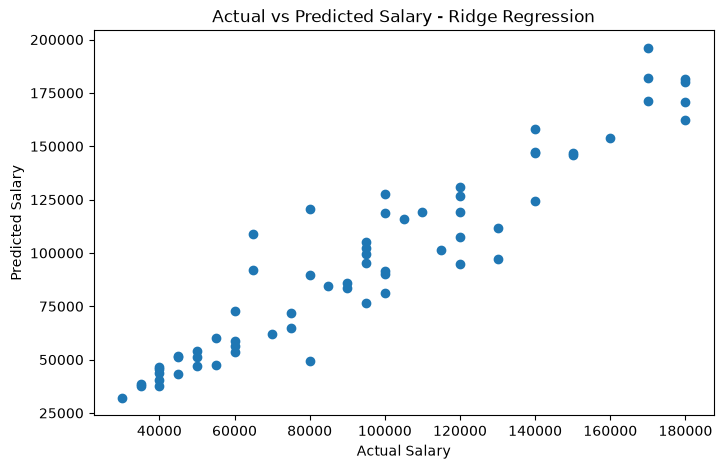

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    tuned_ridge_pred,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

plt.tight_layout()

plt.savefig(
    "../outputs/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 20.Residual Analysis

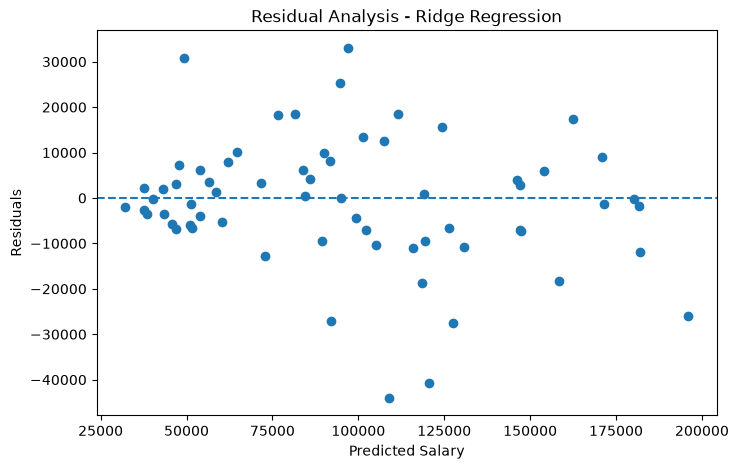

In [ ]:
residuals = y_test - tuned_ridge_pred

plt.figure(figsize=(8, 6))

plt.scatter(
    tuned_ridge_pred,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Salary")
plt.ylabel("Residual")
plt.title("Residual Analysis")

plt.tight_layout()

plt.savefig(
    "../outputs/residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Recreating original dataset 

In [ ]:
# ============================================================
# RECREATE CLEAN ORIGINAL DATASET
# ============================================================

import pandas as pd

original_df = pd.read_csv("../data/raw/Salary _Data.csv")

# Remove completely empty rows
original_df = original_df.dropna(how="all")

# Remove duplicate rows
original_df = original_df.drop_duplicates()

print("Dataset Shape:", original_df.shape)
print("\nColumns:")
print(original_df.columns.tolist())

Dataset Shape: (324, 6)

Columns:
['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary']


### Final prediction using a test employee

In [ ]:
# Final Prediction Example

sample = X_test.iloc[[0]]
actual_salary = y_test.iloc[0]

# Get original employee details
employee = original_df.loc[sample.index].iloc[0]

# Predict salary
predicted_salary = best_model.predict(sample)[0]

print("Employee Details")
print("-" * 35)

print(f"Age                 : {employee['Age']}")
print(f"Gender              : {employee['Gender']}")
print(f"Education Level     : {employee['Education Level']}")
print(f"Job Title           : {employee['Job Title']}")
print(f"Years of Experience : {employee['Years of Experience']}")

print("\nSalary Prediction")
print("-" * 35)

print(f"Actual Salary       : ₹{actual_salary:,.2f}")
print(f"Predicted Salary    : ₹{predicted_salary:,.2f}")
print(f"Difference          : ₹{abs(actual_salary - predicted_salary):,.2f}")

Employee Details
-----------------------------------
Age                 : 40.0
Gender              : Female
Education Level     : Master's
Job Title           : Senior Training Specialist
Years of Experience : 12.0

Salary Prediction
-----------------------------------
Actual Salary       : ₹100,000.00
Predicted Salary    : ₹118,606.61
Difference          : ₹18,606.61


### New Employee Salary Prediction

In [ ]:
new_employee = pd.DataFrame({
    "Age": [40],
    "Gender": ["Female"],
    "Education Level": ["Master's"],
    "Job Title": ["Senior Training Specialist"],
    "Years of Experience": [12]
})

predicted_salary = tuned_ridge.predict(new_employee)

print(f"Predicted Salary: ₹{predicted_salary[0]:,.2f}")

New Employee Salary Prediction
-----------------------------------
Age                 : 28
Gender              : Male
Education Level     : Master's
Job Title           : Software Engineer
Years of Experience : 4
Predicted Salary    : ₹82,131.34


In [ ]:
from scipy.stats import f

# Values from your project
R2 = 0.8943
n = 259
k = 181

# Calculate F-statistic
F_stat = (R2 / (1 - R2)) * ((n - k - 1) / k)

# Degrees of freedom
df1 = k
df2 = n - k - 1

# Calculate p-value
p_value = f.sf(F_stat, df1, df2)

print("F-Test Hypothesis Testing")
print("-" * 35)

print(f"R²          : {R2:.4f}")
print(f"F-statistic : {F_stat:.4f}")
print(f"df1         : {df1}")
print(f"df2         : {df2}")
print(f"p-value     : {p_value:.10e}")

# Decision
alpha = 0.05

print(f"\nSignificance Level (α): {alpha}")

if p_value < alpha:
    print("Decision: Reject H0")
    print("Conclusion: The regression model is statistically significant.")
else:
    print("Decision: Fail to reject H0")
    print("Conclusion: The regression model is not statistically significant.")

F-Test Hypothesis Testing
-----------------------------------
R²          : 0.8943
F-statistic : 3.5993
df1         : 181
df2         : 77
p-value     : 1.2512177350e-09

Significance Level (α): 0.05
Decision: Reject H0
Conclusion: The regression model is statistically significant.


In [ ]:
os.makedirs("../outputs", exist_ok=True)

results_df.to_csv(
    "../outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")


### Conclusion

The F-test produced an F-statistic of 3.5993 and a p-value of 1.2512 × 10⁻⁹. Since the p-value is much smaller than the significance level of 0.05, the null hypothesis is rejected. Therefore, there is a statistically significant relationship between the predictor variables and Salary. The model also has an R² value of 0.8943, indicating strong explanatory performance